# Week 5: Sudden Market Crashes: A Merton-Style Jump Model

**Project:** *Valuing Variable Annuity Guarantees Under Market Crashes and Regime Shifts*  
**Mentor:** Hao Quan  
**Notebook type:** all-in-one lesson, lab, exercises, and worked solutions

> **Driving question:** What guarantee risk is missed when the account is forced to move continuously?

## Learning goals

- Interpret Poisson jump arrival intensity and lognormal jump size.
- Simulate terminal values and full paths under jump diffusion.
- Apply and verify the risk-neutral jump compensator.
- Compare GMAB value and tail diagnostics with smooth GBM.
- Separate illustrative pricing assumptions from historical crash frequencies.

## How to use this notebook

1. Complete the assigned reading before the weekly meeting.
2. Read the explanation cells and predict each result before running the code.
3. Run the notebook from top to bottom. Every random experiment uses a fixed seed.
4. Attempt the exercises before opening the worked-solution section.
5. Write a 150–250 word interpretation of the main result in your own words.

This notebook is educational. It simplifies real contracts and is not an insurance
quotation, investment recommendation, or complete actuarial valuation.

## Assigned reading

- [Merton (1976), Option Pricing When Underlying Stock Returns Are Discontinuous](https://dspace.mit.edu/entities/publication/e63635d9-d2bf-40ce-a79b-67786dd9f105) — read the abstract and journal pp. 125–129; pp. 132–135 are optional mentor-led reading
- [NYU risk-neutral notes](https://math.nyu.edu/faculty/kohn/cont-time-finance/section3.pdf) — revisit the incomplete-market discussion on pp. 4–5


In [12]:
import math
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.set_printoptions(precision=4, suppress=True)

SEED = 20260730
rng = np.random.default_rng(SEED)
print(f"Reproducible random seed: {SEED}")


Reproducible random seed: 20260730


## 1. Model and interpretation

A Merton-style account under a chosen pricing measure is

$$
\frac{dA_t}{A_{t^-}}
=(r-c-\lambda\kappa)dt+\sigma dW_t+(J-1)dN_t,
$$

where

- $N_t$ is a Poisson process with intensity $\lambda$ per year;
- $\log J\sim N(\mu_J,\delta_J^2)$;
- $\kappa=E[J-1]=e^{\mu_J+\delta_J^2/2}-1$;
- $-\lambda\kappa$ compensates the expected jump effect.

The jump multiplier $J$ is multiplicative. If $\mu_J=-0.25$, the median
multiplier is $e^{-0.25}\approx0.779$, a drop of about 22.1%—not exactly 25%.

This market is incomplete. The jump parameters below are an **illustrative
$Q$ specification**, not historical estimates and not uniquely implied by
no-arbitrage.


In [13]:
@dataclass(frozen=True)
class JumpGMAB:
    A0: float = 100_000.0
    G: float = 100_000.0
    T: float = 10.0
    r: float = 0.03
    charge: float = 0.02
    sigma: float = 0.16
    jump_intensity: float = 0.15
    mean_log_jump: float = -0.25
    sd_log_jump: float = 0.12


params = JumpGMAB()
print(params)
print(f"Median jump multiplier: {np.exp(params.mean_log_jump):.4f}")
print(f"Median percentage change: {np.exp(params.mean_log_jump) - 1:.2%}")


JumpGMAB(A0=100000.0, G=100000.0, T=10.0, r=0.03, charge=0.02, sigma=0.16, jump_intensity=0.15, mean_log_jump=-0.25, sd_log_jump=0.12)
Median jump multiplier: 0.7788
Median percentage change: -22.12%


## 2. Poisson crash counts


In [14]:
count_rng = np.random.default_rng(SEED + 1)
n_paths = 200_000
counts = count_rng.poisson(params.jump_intensity * params.T, size=n_paths)
target = params.jump_intensity * params.T
print(f"Sample mean count:     {counts.mean():.4f}; target: {target:.4f}")
print(f"Sample variance count: {counts.var(ddof=1):.4f}; target: {target:.4f}")
print(pd.Series(counts).value_counts(normalize=True).sort_index().head(8).rename("probability"))

assert abs(counts.mean() - target) < 0.02
assert abs(counts.var(ddof=1) - target) < 0.03


Sample mean count:     1.5017; target: 1.5000
Sample variance count: 1.4971; target: 1.5000
0   0.2223
1   0.3349
2   0.2511
3   0.1263
4   0.0470
5   0.0142
6   0.0034
7   0.0007
Name: probability, dtype: float64


## 3. Exact terminal simulation

Conditional on $N_T=n$, the sum of log jumps is normal:

$$\sum_{j=1}^{N_T}\log J_j
\mid N_T=n\sim N(n\mu_J,n\delta_J^2).$$


In [15]:
def jump_compensator(mean_log_jump, sd_log_jump):
    return np.exp(mean_log_jump + 0.5 * sd_log_jump**2) - 1


def simulate_jump_terminal(p, n_paths, seed=SEED, compensate=True):
    generator = np.random.default_rng(seed)
    n_jumps = generator.poisson(p.jump_intensity * p.T, size=n_paths)
    z_diffusion = generator.standard_normal(n_paths)
    z_jump = generator.standard_normal(n_paths)
    aggregate_log_jump = (
        n_jumps * p.mean_log_jump
        + np.sqrt(n_jumps) * p.sd_log_jump * z_jump
    )
    kappa = jump_compensator(p.mean_log_jump, p.sd_log_jump)
    compensation = p.jump_intensity * kappa if compensate else 0.0
    log_terminal = (
        np.log(p.A0)
        + (p.r - p.charge - compensation - 0.5 * p.sigma**2) * p.T
        + p.sigma * np.sqrt(p.T) * z_diffusion
        + aggregate_log_jump
    )
    return np.exp(log_terminal), n_jumps


terminal_jump, n_jumps = simulate_jump_terminal(params, 250_000, seed=SEED + 2)
theory_mean = params.A0 * np.exp((params.r - params.charge) * params.T)
sample_se = terminal_jump.std(ddof=1) / np.sqrt(len(terminal_jump))
print(f"Simulated E_Q[A_T]: ${terminal_jump.mean():,.2f}")
print(f"Theoretical E_Q[A_T]: ${theory_mean:,.2f}")
print(f"Difference in MC SE units: {(terminal_jump.mean() - theory_mean) / sample_se:.2f}")

assert (terminal_jump > 0).all()
assert abs(terminal_jump.mean() - theory_mean) < 4 * sample_se


Simulated E_Q[A_T]: $110,540.58
Theoretical E_Q[A_T]: $110,517.09
Difference in MC SE units: 0.17


## 4. What goes wrong without the compensator?

Negative jumps reduce the raw expected growth. Risk-neutral drift compensation
restores the selected expected account growth $A_0e^{(r-c)T}$. This adjustment
does **not** remove tail risk.


In [7]:
terminal_bad, _ = simulate_jump_terminal(
    params, 250_000, seed=SEED + 2, compensate=False
)
comp_check = pd.DataFrame({
    "model": ["with compensator", "without compensator", "theory"],
    "mean_terminal_account": [terminal_jump.mean(), terminal_bad.mean(), theory_mean],
})
print(comp_check.to_string(index=False, formatters={"mean_terminal_account": "${:,.2f}".format}))
assert terminal_bad.mean() < theory_mean * 0.85


              model mean_terminal_account
   with compensator           $110,540.58
without compensator            $79,999.89
             theory           $110,517.09


## 5. Monthly path simulation

The grid is used only to draw pictures and later accommodate path-dependent
features. Poisson counts allow zero, one, or multiple jumps per month.


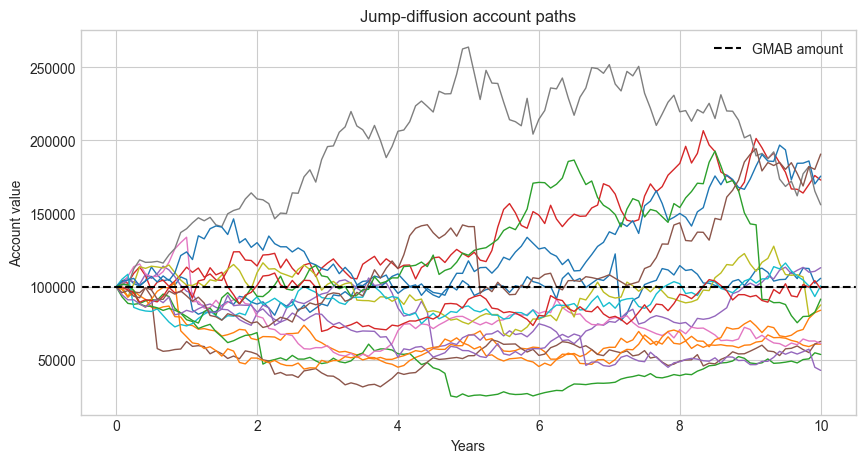

Displayed paths with no jumps: 4
Displayed paths with 1+ jumps: 12


In [8]:
def simulate_jump_paths(p, n_paths=20, n_steps=120, seed=SEED):
    generator = np.random.default_rng(seed)
    dt = p.T / n_steps
    counts = generator.poisson(p.jump_intensity * dt, size=(n_paths, n_steps))
    z_diff = generator.standard_normal((n_paths, n_steps))
    z_jump = generator.standard_normal((n_paths, n_steps))
    log_jumps = (
        counts * p.mean_log_jump
        + np.sqrt(counts) * p.sd_log_jump * z_jump
    )
    kappa = jump_compensator(p.mean_log_jump, p.sd_log_jump)
    log_increments = (
        (p.r - p.charge - p.jump_intensity * kappa - 0.5 * p.sigma**2) * dt
        + p.sigma * np.sqrt(dt) * z_diff
        + log_jumps
    )
    log_paths = np.column_stack([
        np.full(n_paths, np.log(p.A0)),
        np.log(p.A0) + np.cumsum(log_increments, axis=1),
    ])
    return np.linspace(0, p.T, n_steps + 1), np.exp(log_paths), counts


time, jump_paths, monthly_counts = simulate_jump_paths(params, n_paths=16, seed=SEED + 3)
fig, ax = plt.subplots(figsize=(10, 5))
for i in range(len(jump_paths)):
    ax.plot(time, jump_paths[i], linewidth=1)
ax.axhline(params.G, color="black", linestyle="--", label="GMAB amount")
ax.set(title="Jump-diffusion account paths", xlabel="Years", ylabel="Account value")
ax.legend()
plt.show()

print(f"Displayed paths with no jumps: {(monthly_counts.sum(axis=1) == 0).sum()}")
print(f"Displayed paths with 1+ jumps: {(monthly_counts.sum(axis=1) >= 1).sum()}")


## 6. Poisson-mixture price benchmark

Conditional on $N_T=n$, $\log A_T$ is normal. We can therefore value the
put-like payoff in each component and weight by Poisson probabilities. The
omitted Poisson tail is controlled explicitly.


In [9]:
def expected_put_from_log_normal(log_mean, log_variance, strike):
    if log_variance < 1e-16:
        return max(strike - np.exp(log_mean), 0.0)
    sd = np.sqrt(log_variance)
    a = (np.log(strike) - log_mean) / sd
    return strike * norm.cdf(a) - np.exp(log_mean + 0.5 * log_variance) * norm.cdf(a - sd)


def gmab_jump_poisson_mixture(p, tail_tolerance=1e-12):
    lam_T = p.jump_intensity * p.T
    kappa = jump_compensator(p.mean_log_jump, p.sd_log_jump)
    probability = np.exp(-lam_T)
    cumulative = 0.0
    undiscounted_value = 0.0
    n = 0
    while True:
        log_mean = (
            np.log(p.A0)
            + (p.r - p.charge - p.jump_intensity * kappa - 0.5 * p.sigma**2) * p.T
            + n * p.mean_log_jump
        )
        log_variance = p.sigma**2 * p.T + n * p.sd_log_jump**2
        undiscounted_value += probability * expected_put_from_log_normal(
            log_mean, log_variance, p.G
        )
        cumulative += probability
        if 1 - cumulative < tail_tolerance:
            break
        n += 1
        probability *= lam_T / n
        if n > 10_000:
            raise RuntimeError("Poisson mixture did not converge")
    return np.exp(-p.r * p.T) * undiscounted_value, n, 1 - cumulative


mixture_value, max_count, omitted_tail = gmab_jump_poisson_mixture(params)
discounted_jump_losses = np.exp(-params.r * params.T) * np.maximum(
    params.G - terminal_jump, 0
)
mc_price = discounted_jump_losses.mean()
mc_se = discounted_jump_losses.std(ddof=1) / np.sqrt(len(discounted_jump_losses))
print(f"Poisson-mixture value: ${mixture_value:,.2f}")
print(f"Monte Carlo value:     ${mc_price:,.2f} (SE ${mc_se:,.2f})")
print(f"Largest jump count included: {max_count}; omitted probability: {omitted_tail:.2e}")

assert omitted_tail < 1e-12
assert abs(mc_price - mixture_value) < 4 * mc_se


Poisson-mixture value: $14,605.20
Monte Carlo value:     $14,636.24 (SE $35.64)
Largest jump count included: 16; omitted probability: 6.74e-13


## 7. Compare jump diffusion with smooth GBM


         model  GMAB_value  trigger_probability  conditional_shortfall
    Smooth GBM 11,974.3388                  NaN                    NaN
Jump diffusion 14,636.2394               0.5419            36,461.7214
Jump-model uplift over GBM: $2,630.86 (22.0%)


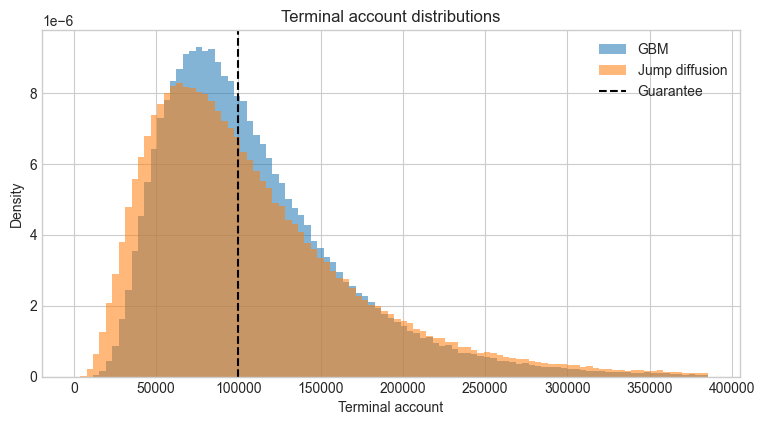

In [10]:
def gbm_closed_form(A0, G, T, r, charge, sigma):
    if sigma == 0:
        return np.exp(-r*T) * max(G - A0*np.exp((r-charge)*T), 0)
    d1 = (np.log(A0/G) + (r-charge+0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return G*np.exp(-r*T)*norm.cdf(-d2) - A0*np.exp(-charge*T)*norm.cdf(-d1)


gbm_value = gbm_closed_form(
    params.A0, params.G, params.T, params.r, params.charge, params.sigma
)
trigger = terminal_jump < params.G
comparison = pd.DataFrame([
    ["Smooth GBM", gbm_value, np.nan, np.nan],
    ["Jump diffusion", mc_price, trigger.mean(), np.maximum(params.G-terminal_jump[trigger], 0).mean()],
], columns=["model", "GMAB_value", "trigger_probability", "conditional_shortfall"])
print(comparison.to_string(index=False))
print(f"Jump-model uplift over GBM: ${mixture_value - gbm_value:,.2f} ({mixture_value/gbm_value - 1:.1%})")

gbm_rng = np.random.default_rng(SEED + 4)
gbm_terminal = params.A0 * np.exp(
    (params.r-params.charge-0.5*params.sigma**2)*params.T
    + params.sigma*np.sqrt(params.T)*gbm_rng.standard_normal(len(terminal_jump))
)

fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.linspace(0, np.quantile(np.concatenate([gbm_terminal, terminal_jump]), 0.995), 100)
ax.hist(gbm_terminal, bins=bins, density=True, alpha=0.55, label="GBM")
ax.hist(terminal_jump, bins=bins, density=True, alpha=0.55, label="Jump diffusion")
ax.axvline(params.G, color="black", linestyle="--", label="Guarantee")
ax.set(title="Terminal account distributions", xlabel="Terminal account", ylabel="Density")
ax.legend()
plt.show()


The jump model here adds jump variance while keeping the same diffusion
volatility. The higher value is therefore calibration-specific, not a theorem.
A fair empirical comparison would calibrate all models to common market data;
that is beyond this seven-week project.

## 8. Sensitivity to jump frequency and severity


            lambda=0.00  lambda=0.05  lambda=0.10  lambda=0.15  lambda=0.25
mu_J=-0.10  11,974.3400  12,293.3300  12,605.7200  12,911.8200  13,506.4000
mu_J=-0.20  11,974.3400  12,647.3000  13,292.8400  13,913.3200  15,087.4900
mu_J=-0.30  11,974.3400  13,192.2300  14,327.7600  15,391.4700  17,339.8300
mu_J=-0.40  11,974.3400  13,877.4400  15,597.0600  17,163.4500  19,940.3200


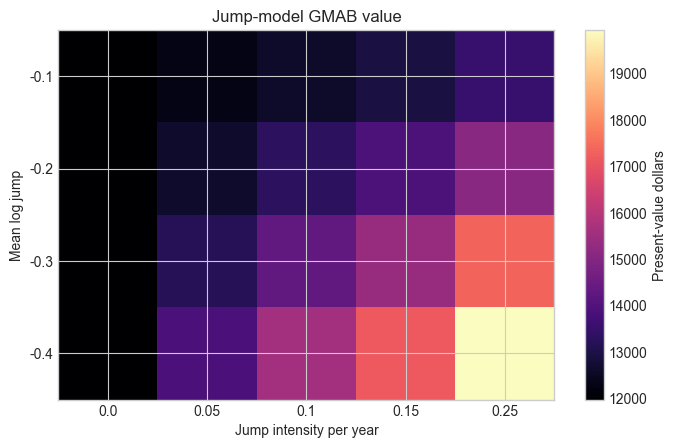

In [11]:
lambda_grid = np.array([0.00, 0.05, 0.10, 0.15, 0.25])
mu_grid = np.array([-0.10, -0.20, -0.30, -0.40])
heat = np.empty((len(mu_grid), len(lambda_grid)))
for i, mu_j in enumerate(mu_grid):
    for j, lam in enumerate(lambda_grid):
        p = JumpGMAB(
            jump_intensity=float(lam),
            mean_log_jump=float(mu_j),
            sd_log_jump=params.sd_log_jump,
        )
        heat[i, j] = gmab_jump_poisson_mixture(p)[0]

heat_df = pd.DataFrame(
    heat,
    index=[f"mu_J={x:.2f}" for x in mu_grid],
    columns=[f"lambda={x:.2f}" for x in lambda_grid],
)
print(heat_df.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(heat, aspect="auto", cmap="magma")
ax.set_xticks(np.arange(len(lambda_grid)), lambda_grid)
ax.set_yticks(np.arange(len(mu_grid)), mu_grid)
ax.set(xlabel="Jump intensity per year", ylabel="Mean log jump", title="Jump-model GMAB value")
fig.colorbar(im, ax=ax, label="Present-value dollars")
plt.show()

assert np.allclose(heat[:, 0], gbm_value)


## 9. Exercises

1. Set $\lambda=0$ and verify that the jump-mixture price equals the GBM price.
2. Remove the compensator and explain the mean error.
3. Change $\mu_J$ from $-0.25$ to $-0.40$ and report the change in value and
   trigger probability.
4. Explain why a historical crash rate is not automatically a risk-neutral
   jump intensity.


## 10. Worked solutions


In [ ]:
# Exercise 1
no_jump = JumpGMAB(jump_intensity=0.0)
no_jump_value = gmab_jump_poisson_mixture(no_jump)[0]
print(f"lambda=0 mixture: ${no_jump_value:,.6f}; GBM: ${gbm_value:,.6f}")

# Exercise 3
severe = JumpGMAB(mean_log_jump=-0.40)
severe_value = gmab_jump_poisson_mixture(severe)[0]
severe_terminal, _ = simulate_jump_terminal(severe, 200_000, seed=SEED + 5)
print(f"Baseline jump value: ${mixture_value:,.2f}")
print(f"More severe-jump value: ${severe_value:,.2f}")
print(f"More severe-jump trigger probability: {(severe_terminal < severe.G).mean():.2%}")

assert np.isclose(no_jump_value, gbm_value, rtol=1e-10, atol=1e-8)
assert severe_value > mixture_value


## 11. Weekly takeaways

1. GBM cannot jump; jump diffusion can create gap risk.
2. Jump intensity controls arrival frequency, while $J$ controls severity.
3. The compensator preserves the chosen risk-neutral mean.
4. The guarantee is sensitive to the lower tail, not merely the average.
5. Jump-model values depend on an explicit, non-unique $Q$ specification.

### Weekly submission

- Completed notebook
- Two-page GBM-versus-jump comparison
- A paragraph explaining the compensating drift
